In [1]:
from typing import TypedDict, Literal
from IPython.display import display, Markdown, Image
from langgraph.graph import StateGraph, START, END
import os

In [4]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
HAS_OPENAI_KEY = bool(os.getenv("OPENAI_API_KEY"))

llm = (
    ChatOpenAI(
        model=MODEL_NAME,
        temperature=0,
        timeout=60,
        max_retries=2,
    )
    if HAS_OPENAI_KEY else None
)

In [8]:
from pydantic import BaseModel, Field

class StepPlan(BaseModel):
    steps: list[str] = Field(description="Ordered, specific, executable steps")

class ReplanDecision(BaseModel):
    remaining_steps: list[str] = Field(description="Steps still needed, or [] when complete")
    reason: str = Field(description="Short explanation")

class PlanningState(TypedDict):
    objective: str
    plan: list[str]
    completed: list[str]
    artifacts: list[str]
    iterations: int
    max_iterations: int
    decision_reason: str

def planning_node(state: PlanningState):
    planner = llm.with_structured_output(StepPlan)
    result = planner.invoke(
        "Design 3 concise, sequential steps for this task. Each step should "
        "produce a small, tangible teaching deliverable. "
        f"Task: {state['objective']}"
    )
    if not result.steps:
        raise ValueError("Planner returned zero steps")
    return {"plan": result.steps}

def execution_node(state: PlanningState):
    if not state["plan"]:
        return {}
    current = state["plan"][0]
    reply = llm.invoke(
        "Complete exactly this one step as a concise, useful deliverable. "
        "Do not claim you searched the web or ran external tools.\n"
        f"Overall objective: {state['objective']}\n"
        f"Current step: {current}\n"
        f"Work already done: {state['artifacts']}"
    )
    artifact = str(reply.content)
    print(f"\nEXECUTED: {current}\n{artifact[:450]}\n")
    return {
        "completed": state["completed"] + [current],
        "artifacts": state["artifacts"] + [artifact],
        "plan": state["plan"][1:],
        "iterations": state["iterations"] + 1
    }

def replan_node(state: PlanningState):
    if not state["plan"]:
        return {"decision_reason": "All original steps executed"}
    replanner = llm.with_structured_output(ReplanDecision)
    decision = replanner.invoke(
        "Given the objective, completed steps, and still planned steps, "
        "return ONLY the genuinely needed remaining tasks. Do not repeat completed tasks. "
        "Keep at most 3 remaining steps. Return [] if the objective is complete.\n"
        f"Objective: {state['objective']}\n"
        f"Completed: {state['completed']}\n"
        f"Pending: {state['plan']}\n"
        f"Artifacts: {[x[:300] for x in state['artifacts']]}"
    )
    return {
        "plan": decision.remaining_steps[:3],
        "decision_reason": decision.reason
    }

def route_planning(state: PlanningState) -> Literal["execute", "__end__"]:
    if state["iterations"] >= state["max_iterations"] or not state["plan"]:
        return END
    return "execute"

planning_builder = StateGraph(PlanningState)
planning_builder.add_node("planner", planning_node)
planning_builder.add_node("execute", execution_node)
planning_builder.add_node("replan", replan_node)
planning_builder.add_edge(START, "planner")
planning_builder.add_edge("planner", "execute")
planning_builder.add_edge("execute", "replan")
planning_builder.add_conditional_edges(
    "replan", route_planning, {"execute": "execute", END: END}
)
planning_graph = planning_builder.compile()

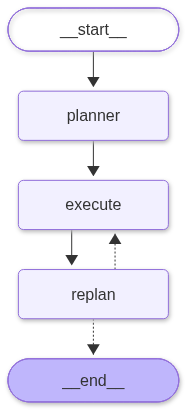

In [9]:
planning_graph

In [10]:
planning_result = planning_graph.invoke(
        {
            "objective": "Prepare a beginner-friendly 45-minute workshop on RAG",
            "plan": [], "completed": [], "artifacts": [],
            "iterations": 0, "max_iterations": 4, "decision_reason": "",
        },
        config={"recursion_limit": 25},
    )


EXECUTED: Define the objectives and key concepts of RAG (Retrieval-Augmented Generation) to create a clear outline for the workshop. Deliverable: A one-page workshop outline with objectives and key concepts.
### Workshop Outline: Introduction to Retrieval-Augmented Generation (RAG)

**Workshop Title:** Unlocking the Power of Retrieval-Augmented Generation (RAG)

**Duration:** 45 Minutes

---

#### **Objectives:**
1. **Understand RAG Fundamentals:** 
   - Define Retrieval-Augmented Generation and its significance in natural language processing.
   
2. **Explore RAG Components:**
   - Identify the key components of RAG, including retrieval mechanisms a


EXECUTED: Develop engaging presentation slides that explain RAG, including examples and visuals to aid understanding. Deliverable: A PowerPoint presentation with at least 10 slides covering the main topics of the workshop.
### PowerPoint Presentation: Unlocking the Power of Retrieval-Augmented Generation (RAG)

#### Slide 1: Title Slide